In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
airline_data = pd.read_csv("/train.csv")

In [3]:
airline_data

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,699630,57,612,2,1,1,1,1,3,3,...,2,2,4,0,0.0,Female,Loyal Customer,Business travel,Eco,False
699631,699631,30,862,2,2,2,3,4,2,4,...,4,2,4,24,34.0,Female,disloyal Customer,Business travel,Eco,False
699632,699632,49,3148,5,5,5,5,4,4,4,...,5,5,5,0,0.0,Male,Loyal Customer,Business travel,Business,True
699633,699633,61,679,5,2,2,2,5,4,4,...,5,5,1,0,0.0,Female,Loyal Customer,Business travel,Eco,True


###we have the Target value , y given so it a Supervised classification problem.

In [4]:
airline_data.isna().sum()

,0
id,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0


In [5]:
airline_data.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='object')

###**drop the null values as they are only 1 in each column  only in Arrival Delay in Minutes  there are 292 null values . we will remove the rest and impute values for Arrival Delay in Minutes  column **

In [6]:
#'few columns have null values in 1 place, so removing only the null entry places
airline_data.dropna(subset=['Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'], inplace=True)

In [7]:
airline_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [8]:
#impute Arrival Delay in Minutes missing values
airline_data['Arrival Delay in Minutes'].mean().round(2)


np.float64(1.13)

In [9]:
airline_data['Arrival Delay in Minutes'].median()

0.0

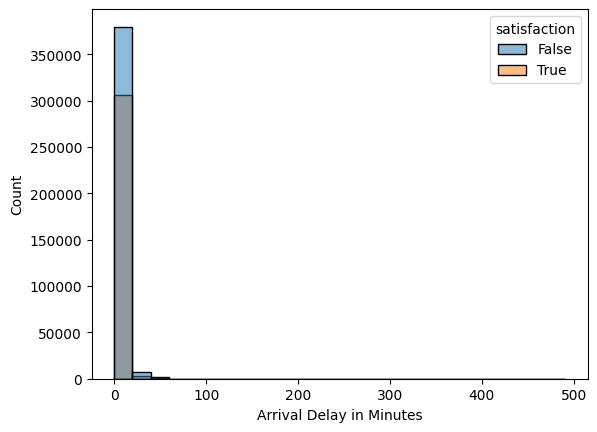

In [10]:
#histplot
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data = airline_data,x= 'Arrival Delay in Minutes',hue='satisfaction',binwidth=20)
plt.show()

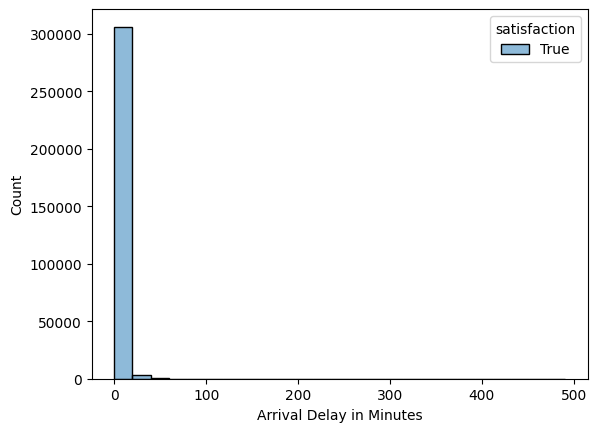

In [11]:
satisfied = airline_data[airline_data['satisfaction']==True]

sns.histplot(data = satisfied,x= 'Arrival Delay in Minutes',hue='satisfaction',binwidth=20)
plt.show()

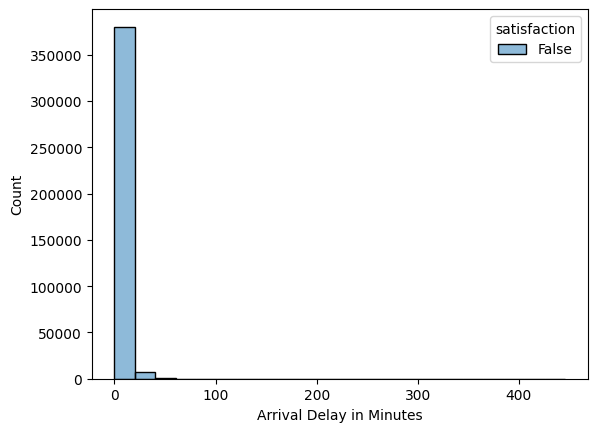

In [12]:
unsatisfied = airline_data[airline_data['satisfaction']==False]

sns.histplot(data = unsatisfied,x= 'Arrival Delay in Minutes',hue='satisfaction',binwidth=20)
plt.show()

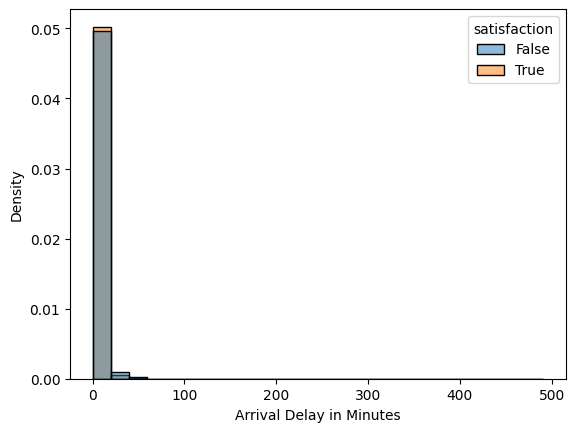

In [13]:
sns.histplot(data = airline_data,x= 'Arrival Delay in Minutes',hue='satisfaction',binwidth=20,stat='density',common_norm=False)
plt.show()

In [14]:
airline_data.groupby("satisfaction")['Arrival Delay in Minutes'].median()

,Arrival Delay in Minutes
satisfaction,
False,0.0
True,0.0


In [15]:
airline_data.groupby("satisfaction")['Arrival Delay in Minutes'].var()

,Arrival Delay in Minutes
satisfaction,
False,40.211931
True,23.878658


In [16]:
#percentage of passengers based on satisfaction
(airline_data.groupby('satisfaction')['Arrival Delay in Minutes'].apply(lambda x: (x > 0).mean() * 100))

,Arrival Delay in Minutes
satisfaction,
False,9.820034
True,6.669803


In [17]:
#now since the 9.7 % passengers reported arirval delay & 6.5  % did not experience .
#Now we would need to see if the data is fuly cleaned & split the data into train & test
airline_data.isna().sum()

,0
id,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0


In [18]:
airline_data.dtypes

,0
id,int64
Age,int64
Flight Distance,int64
Inflight wifi service,int64
Departure/Arrival time convenient,int64
Ease of Online booking,int64
Gate location,int64
Food and drink,int64
Online boarding,int64
Seat comfort,int64


In [19]:
#the obejct columns need to be changes to Float or int, we could do that by encoding
#Gender	object
#Customer Type	object
#Type of Travel	object
#Class	object
#satisfaction	object

In [20]:
X= airline_data.drop('satisfaction',axis=1)
X

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,0,36,694,4,4,4,3,1,4,1,...,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco
1,1,56,651,5,5,5,5,5,4,4,...,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business
2,2,31,1371,3,4,2,5,3,3,3,...,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco
3,3,10,1616,3,5,3,3,3,3,3,...,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco
4,4,23,481,3,4,3,4,5,3,5,...,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,699630,57,612,2,1,1,1,1,3,3,...,2,2,2,4,0,0.0,Female,Loyal Customer,Business travel,Eco
699631,699631,30,862,2,2,2,3,4,2,4,...,5,4,2,4,24,34.0,Female,disloyal Customer,Business travel,Eco
699632,699632,49,3148,5,5,5,5,4,4,4,...,5,5,5,5,0,0.0,Male,Loyal Customer,Business travel,Business
699633,699633,61,679,5,2,2,2,5,4,4,...,5,5,5,1,0,0.0,Female,Loyal Customer,Business travel,Eco


In [21]:
y=airline_data['satisfaction']
y

,satisfaction
0,False
1,True
2,False
3,False
4,False
...,...
699630,False
699631,False
699632,True
699633,True


In [22]:
#use one hot encoding
y.unique()

array([False,  True])

In [23]:
y= y.map({True: 1, False:0})
y

,satisfaction
0,0
1,1
2,0
3,0
4,0
...,...
699630,0
699631,0
699632,1
699633,1


In [24]:
print(y.isna().sum())
print(y.dtype)
y.unique()

0
int64


array([0, 1])

In [25]:
#moving on to the X features
#Gender	object
#Customer Type	object
#Type of Travel	object
#Class	object

X.Gender.unique()

array(['Female', 'Male'], dtype=object)

In [26]:
X['Customer Type'].unique()

array(['Loyal Customer', 'disloyal Customer'], dtype=object)

In [27]:
X['Type of Travel'].unique()

array(['Personal Travel', 'Business travel'], dtype=object)

In [28]:
X['Class'].unique()

array(['Eco', 'Business', 'Eco Plus'], dtype=object)

In [29]:
cat_columns = ['Gender','Class','Type of Travel','Customer Type']
X= pd.get_dummies(X, columns= cat_columns, dtype= int)
X

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Arrival Delay in Minutes,Gender_Female,Gender_Male,Class_Business,Class_Eco,Class_Eco Plus,Type of Travel_Business travel,Type of Travel_Personal Travel,Customer Type_Loyal Customer,Customer Type_disloyal Customer
0,0,36,694,4,4,4,3,1,4,1,...,0.0,1,0,0,1,0,0,1,1,0
1,1,56,651,5,5,5,5,5,4,4,...,0.0,0,1,1,0,0,1,0,1,0
2,2,31,1371,3,4,2,5,3,3,3,...,0.0,1,0,0,1,0,0,1,1,0
3,3,10,1616,3,5,3,3,3,3,3,...,0.0,0,1,0,1,0,0,1,1,0
4,4,23,481,3,4,3,4,5,3,5,...,0.0,1,0,0,1,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,699630,57,612,2,1,1,1,1,3,3,...,0.0,1,0,0,1,0,1,0,1,0
699631,699631,30,862,2,2,2,3,4,2,4,...,34.0,1,0,0,1,0,1,0,0,1
699632,699632,49,3148,5,5,5,5,4,4,4,...,0.0,0,1,1,0,0,1,0,1,0
699633,699633,61,679,5,2,2,2,5,4,4,...,0.0,1,0,0,1,0,1,0,1,0


In [30]:
X.shape

(699635, 27)

In [31]:
y.shape

(699635,)

In [32]:
#Arrival delay column - fillna =0
X['Arrival Delay in Minutes']= X['Arrival Delay in Minutes'].fillna(0)

In [33]:
X.isna().sum()

,0
id,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0


In [34]:
#NOw splitting the Training & Testing data
from sklearn.model_selection import train_test_split

In [35]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size= 0.2,random_state=42,shuffle=True,stratify = y)
X_train,X_test,y_train,y_test

(            id  Age  Flight Distance  Inflight wifi service  \
 159366  159366   50             2454                      1   
 659958  659958   54             1846                      1   
 434666  434666   31             1678                      1   
 427957  427957   22              759                      4   
 409049  409049   21              983                      2   
 ...        ...  ...              ...                    ...   
 210407  210407   54             2611                      3   
 369339  369339   42             3563                      2   
 368516  368516   54              972                      3   
 484078  484078   38             1399                      4   
 241208  241208   37              239                      1   
 
         Departure/Arrival time convenient  Ease of Online booking  \
 159366                                  1                       1   
 659958                                  2                       2   
 434666             

In [36]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((559708, 27), (139927, 27), (559708,), (139927,))

In [37]:
#lets build the Models & see whihc one has the best prediction = Logistic Regression & Random Forest
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [38]:
logistic_model = LogisticRegression()
logistic_model

LogisticRegression()

In [39]:
logistic_model.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [40]:
logistic_pred = logistic_model.predict(X_test)
logistic_pred

array([1, 0, 0, ..., 0, 1, 0])

In [41]:
from sklearn.metrics import accuracy_score

score = accuracy_score(y_test, logistic_pred)

print("Accuracy:", score)
print("Accuracy (%):", score * 100)

Accuracy: 0.7159804755336712
Accuracy (%): 71.59804755336711


In [42]:
from sklearn.metrics import classification_report

print(classification_report(y_test, logistic_pred))

              precision    recall  f1-score   support

           0       0.76      0.71      0.74     77859
           1       0.67      0.72      0.69     62068

    accuracy                           0.72    139927
   macro avg       0.71      0.72      0.71    139927
weighted avg       0.72      0.72      0.72    139927



In [43]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, logistic_pred))

[[55530 22329]
 [17413 44655]]


[[55530 22329]
 [17413 44655]]


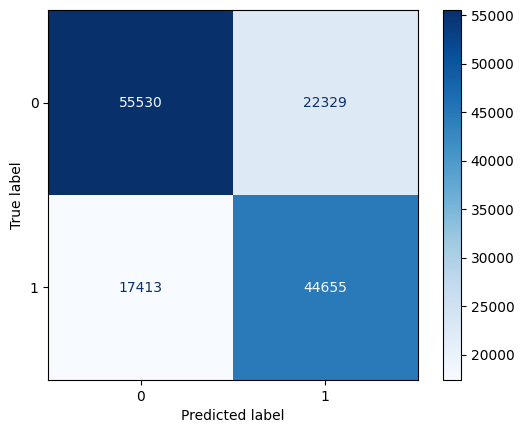

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, logistic_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot(cmap="Blues")

plt.show()

In [45]:
#sclaing the model for better accurac y

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [46]:
scaled_log_model = make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
scaled_log_model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [47]:
y_pred_scaled = scaled_log_model.predict(X_test)

In [48]:
print("Original accuracy:", accuracy_score(y_test, logistic_pred))
print("Scaled accuracy:", accuracy_score(y_test, y_pred_scaled))

Original accuracy: 0.7159804755336712
Scaled accuracy: 0.878079284198189


In [49]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_scaled))

              precision    recall  f1-score   support

           0       0.88      0.90      0.89     77859
           1       0.87      0.85      0.86     62068

    accuracy                           0.88    139927
   macro avg       0.88      0.87      0.88    139927
weighted avg       0.88      0.88      0.88    139927



In [51]:
#Analysing  the errors

results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_scaled})

In [53]:
misclassified = results[results['Actual'] != results['Predicted']]
misclassified

,Actual,Predicted
310446,0,1
214027,0,1
540758,1,0
109187,0,1
521950,1,0
...,...,...
649053,1,0
283206,1,0
202515,1,0
291411,1,0


In [54]:
print("Total test passengers:", len(results))
print("Misclassified passengers:", len(misclassified))
print("Correct predictions:", len(results) - len(misclassified))
print("Error rate (%):", round(len(misclassified) / len(results) * 100, 2))

Total test passengers: 139927
Misclassified passengers: 17060
Correct predictions: 122867
Error rate (%): 12.19


In [58]:
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_scaled})

comparison = pd.DataFrame({"Actual": results['Actual'].value_counts().sort_index(),
                            "Predicted": results['Predicted'].value_counts().sort_index(),}).fillna(0)

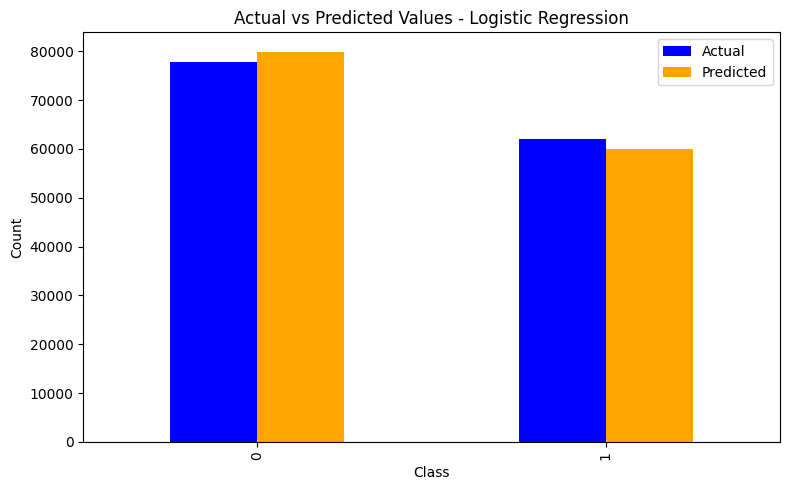

In [59]:
comparison.plot(kind='bar', figsize=(8, 5), color=['blue', 'orange'])

plt.title('Actual vs Predicted Values - Logistic Regression')
plt.xlabel('Class')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

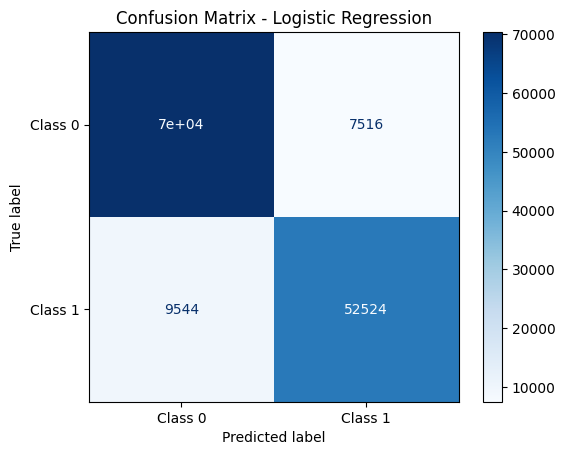

In [60]:
cm = confusion_matrix(y_test, y_pred_scaled)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Class 0', 'Class 1']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

1. Model building: I used Logistic Regression to teach the computer how to make predictions. I split the data into training data (to learn) and testing data (to check how well it learned).

2. Prediction: I used the trained model to predict answers and compared them with the actual answers.

3. Feature scaling: I scaled the data to put numerical values on a similar scale. This helped the model perform better.

4. Results and conclusion: I compared the scaled and unscaled models using accuracy, precision, recall, F1-score, and the confusion matrix. The scaled model performed better, so I chose it as the better model.